# Vehicle Class Prediction — 3-class classification with course-approved models

**Course project (Kaggle-style).** Predict `vehicle_class` ∈ {0, 1, 2} from 20 numeric vehicle specifications.

**Allowed models only:** Gaussian Naive Bayes, LDA, QDA, logistic regression (ridge / lasso) and decision trees.
No random forests, boosting, SVM, KNN or neural networks.

**Workflow:** 1) dataset → 2) EDA → 3) preprocessing and feature selection → 4) validation scheme → 5) models and tuning →
6) results → 7) final prediction → 8) viva notes.

Everything is seeded (`SEED = 42`) and the notebook runs top to bottom. Test labels do not exist, and the test set is never used for any decision.

In [1]:
# --- Imports and global settings ------------------------------------------------------------
import warnings, tempfile, itertools
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

import sklearn
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import (RepeatedStratifiedKFold, StratifiedKFold, GridSearchCV,
                                     cross_val_score, validation_curve)
from sklearn.feature_selection import f_classif, SequentialFeatureSelector, SelectFromModel
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

SEED = 42                      # one seed used everywhere (CV splitters, trees, saga solver)
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

# Switches (leave as they are for the submitted results)
DEDUPLICATE = True             # drop exact duplicate training rows (see Section 1)
RUN_NESTED = True              # optional nested-CV optimism check at the end of Section 6

# QDA at reg_param=0 warns about collinear variables; that is expected here and discussed in Section 5.4.
warnings.filterwarnings("ignore", message="Variables are collinear")
warnings.filterwarnings("ignore", category=PendingDeprecationWarning)   # seaborn/matplotlib 'vert' notice, harmless

SK_VER = tuple(int(p) for p in sklearn.__version__.split(".")[:2])
print("scikit-learn", sklearn.__version__)

scikit-learn 1.6.1


## 1. Problem and dataset

* **Task:** multi-class classification, `vehicle_class` ∈ {0, 1, 2}, 20 numeric features (engine, dimensions, fuel economy, performance, battery...).
* **Metric:** accuracy (classes are balanced, so accuracy is a fair summary).
* **Files:** `vehicle_train_10000.csv` (labelled), `vehicle_test.csv` (unlabelled), `vehicle_sample_submission.csv` (format).
* `vehicle_id` is only a row index: it is **excluded from the features** and kept only to build the submission file.

Put the three CSVs next to this notebook (or in any sub-folder of it); the cell below finds them.

In [2]:
# --- Load data -----------------------------------------------------------------------------
import zipfile

SEARCH_DIRS = [Path("."), Path("/kaggle/input"), Path("/content")]   # current folder, Kaggle, Colab

def find_csv(name):
    """Look for a CSV in the search folders (and sub-folders); also look inside any .zip found there."""
    for base in SEARCH_DIRS:
        if not base.exists():
            continue
        hits = sorted(base.rglob(name))
        if hits:
            return hits[0]
        for z in sorted(base.rglob("*.zip")):          # not unzipped yet: extract into the working folder
            with zipfile.ZipFile(z) as zf:
                if any(Path(n).name == name for n in zf.namelist()):
                    zf.extractall(".")
                    return sorted(Path(".").rglob(name))[0]
    raise FileNotFoundError(f"{name} not found - add the dataset as input or add its folder to SEARCH_DIRS.")

train_raw = pd.read_csv(find_csv("vehicle_train_10000.csv"))
test = pd.read_csv(find_csv("vehicle_test.csv"))
sample_sub = pd.read_csv(find_csv("vehicle_sample_submission.csv"))

ID, TARGET = "vehicle_id", "vehicle_class"
FEATURES = [c for c in train_raw.columns if c not in (ID, TARGET)]

print("train :", train_raw.shape)
print("test  :", test.shape)
print("sample:", sample_sub.shape, "->", list(sample_sub.columns))
print("number of features:", len(FEATURES))
print("\nMissing values  train / test:", int(train_raw.isna().sum().sum()), "/", int(test.isna().sum().sum()))
print("\ndtypes:")
print(train_raw.dtypes.value_counts().to_string())
display(train_raw.dtypes.to_frame("dtype").T)
display(train_raw.head())

train : (10000, 22)
test  : (2500, 21)
sample: (2500, 2) -> ['vehicle_id', 'vehicle_class']
number of features: 20

Missing values  train / test: 0 / 0

dtypes:
float64    20
int64       2


,vehicle_id,engine_displacement_l,horsepower_hp,vehicle_weight_kg,wheelbase_mm,vehicle_length_mm,vehicle_width_mm,vehicle_height_mm,fuel_tank_capacity_l,city_fuel_efficiency_kmpl,highway_fuel_efficiency_kmpl,engine_cylinders,torque_nm,ground_clearance_mm,turning_radius_m,cargo_capacity_l,acceleration_0_100_kmh_s,braking_distance_m,tire_width_mm,drag_coefficient,battery_capacity_kwh,vehicle_class
dtype,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,int64


,vehicle_id,engine_displacement_l,horsepower_hp,vehicle_weight_kg,wheelbase_mm,vehicle_length_mm,vehicle_width_mm,vehicle_height_mm,fuel_tank_capacity_l,city_fuel_efficiency_kmpl,highway_fuel_efficiency_kmpl,engine_cylinders,torque_nm,ground_clearance_mm,turning_radius_m,cargo_capacity_l,acceleration_0_100_kmh_s,braking_distance_m,tire_width_mm,drag_coefficient,battery_capacity_kwh,vehicle_class
0,1,2.56,290.0,1532.0,2737.0,4538.0,1814.0,1544.0,65.0,9.69,13.86,7.0,438.0,197.0,6.05,656.0,5.87,43.0,267.0,0.34,79.0,2
1,2,2.70,350.0,1529.0,2726.0,4473.0,1848.0,1636.0,62.0,10.35,14.32,7.0,441.0,251.0,5.30,513.0,6.48,41.0,247.0,0.28,76.0,2
2,3,2.50,335.0,1100.0,2504.0,3900.0,1650.0,1251.0,35.0,13.70,17.60,7.0,471.0,110.0,5.58,150.0,3.90,29.0,261.0,0.23,89.0,2
3,4,3.00,345.0,2069.0,3053.0,5134.0,2036.0,1572.0,81.0,10.72,16.45,7.0,478.0,168.0,6.36,626.0,6.20,51.0,283.0,0.37,60.0,1
4,5,1.59,155.0,1574.0,2791.0,4678.0,1804.0,1492.0,60.0,13.55,16.71,4.0,235.0,179.0,5.43,447.0,10.15,47.0,201.0,0.34,43.0,1


In [3]:
# --- Class balance (raw training file) ---------------------------------------------------------
balance = train_raw[TARGET].value_counts().sort_index().to_frame("count")
balance["share"] = (balance["count"] / len(train_raw)).round(4)
display(balance)

,count,share
vehicle_class,,
0,3389,0.3389
1,3326,0.3326
2,3285,0.3285


### Data integrity check: duplicate rows

Before modelling I check whether any training rows are exact copies of each other, and whether the test set overlaps with the training set.
This matters because **cross-validation assumes validation rows are unseen**: if a row's twin sits in the training fold, the model is
partly graded on data it has memorised.

In [4]:
# --- Duplicate check -------------------------------------------------------------------------
dup_mask = train_raw.duplicated(subset=FEATURES, keep="first")
print("duplicate rows (all 20 features identical to an earlier row):", int(dup_mask.sum()))
print("ids of the duplicate rows:", train_raw.loc[dup_mask, ID].min(), "to", train_raw.loc[dup_mask, ID].max())

# Do duplicates always carry the same label?
max_labels_per_group = train_raw.groupby(FEATURES)[TARGET].nunique().max()
print("max distinct labels inside a duplicate group:", int(max_labels_per_group), "(1 = labels always agree)")

# Does the test set overlap with train? (features only, no labels involved)
overlap = test.merge(train_raw[FEATURES].drop_duplicates(), on=FEATURES, how="inner")
print("test rows identical to a training row:", len(overlap))
print("duplicate rows inside the test set  :", int(test.duplicated(subset=FEATURES).sum()))

duplicate rows (all 20 features identical to an earlier row): 2500
ids of the duplicate rows: 7501 to 10000
max distinct labels inside a duplicate group: 1 (1 = labels always agree)
test rows identical to a training row: 0
duplicate rows inside the test set  : 0


**Finding.** The last 2,500 training rows (ids 7,501 to 10,000) are exact copies of earlier rows with identical labels, so the file holds
only **7,500 unique vehicles**. The test set has no overlap with the training set.

**Decision: drop the duplicates** (`DEDUPLICATE = True`). A copy adds no new information, but with ordinary k-fold CV it lets a row
and its twin land on opposite sides of a split, which inflates validation accuracy for models that memorise (deep trees most of all).
Because the test set contains no copies of training rows, that inflation would not carry over to the real test score, so it would
mislead model selection. Section 4 quantifies the effect. Set `DEDUPLICATE = False` to see the raw behaviour.

working train set: (7500, 20) | test features: (2500, 20)


,count,share
vehicle_class,,
0,2539,0.3385
1,2490,0.3320
2,2471,0.3295


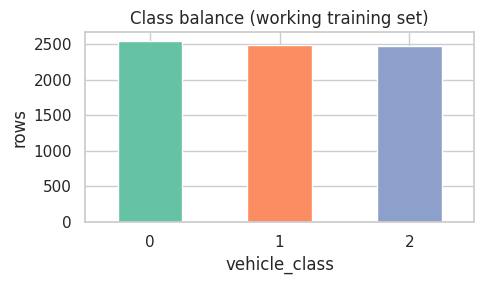

In [5]:
# --- Working training set ---------------------------------------------------------------------
if DEDUPLICATE:
    train = train_raw.drop_duplicates(subset=FEATURES, keep="first").reset_index(drop=True)
else:
    train = train_raw.copy()

X = train[FEATURES]          # vehicle_id is NOT a feature
y = train[TARGET]
X_test = test[FEATURES]      # same column order as training
print("working train set:", X.shape, "| test features:", X_test.shape)

balance = y.value_counts().sort_index().to_frame("count")
balance["share"] = (balance["count"] / len(y)).round(4)
display(balance)

fig, ax = plt.subplots(figsize=(5, 3))
balance["count"].plot.bar(ax=ax, color=sns.color_palette("Set2", 3), rot=0)
ax.set_title("Class balance (working training set)"); ax.set_xlabel("vehicle_class"); ax.set_ylabel("rows")
plt.tight_layout(); plt.show()

## 2. Exploratory data analysis

Goals: see how the classes differ, which features separate them best, and how strongly the features are correlated with each other
(which matters for Naive Bayes). EDA uses the training data only.

In [6]:
# --- Per-class feature means ---------------------------------------------------------------
class_means = train.groupby(TARGET)[FEATURES].mean().T
class_means.columns = [f"class {c}" for c in class_means.columns]
# spread of class means relative to the overall std: a quick "how separated are the classes" indicator
class_means["spread / std"] = (class_means.max(axis=1) - class_means.min(axis=1)) / X.std()
display(class_means.sort_values("spread / std", ascending=False).round(3))

,class 0,class 1,class 2,spread / std
braking_distance_m,39.126,48.290,34.575,1.897
battery_capacity_kwh,64.110,58.522,89.402,1.823
drag_coefficient,0.311,0.351,0.277,1.738
vehicle_width_mm,1781.207,1962.873,1765.989,1.671
wheelbase_mm,2698.783,2961.888,2674.890,1.665
acceleration_0_100_kmh_s,8.621,8.409,4.865,1.664
vehicle_length_mm,4503.521,5041.745,4434.510,1.658
vehicle_weight_kg,1506.018,1951.665,1453.412,1.630
fuel_tank_capacity_l,55.620,75.426,52.281,1.599
torque_nm,314.644,386.157,512.253,1.555


In [7]:
# --- Rank features by ANOVA F (used only to choose which features to PLOT, not for selection) -----
F, p = f_classif(X, y)
f_rank = pd.Series(F, index=FEATURES).sort_values(ascending=False)
display(f_rank.round(1).to_frame("ANOVA F"))
TOP = f_rank.index[:6].tolist()
print("Most informative (univariate):", TOP)

,ANOVA F
battery_capacity_kwh,6239.4
braking_distance_m,6073.1
acceleration_0_100_kmh_s,5165.0
vehicle_width_mm,5068.2
wheelbase_mm,4908.7
vehicle_length_mm,4528.8
vehicle_weight_kg,4270.7
drag_coefficient,3754.3
fuel_tank_capacity_l,3690.1
horsepower_hp,2648.1


Most informative (univariate): ['battery_capacity_kwh', 'braking_distance_m', 'acceleration_0_100_kmh_s', 'vehicle_width_mm', 'wheelbase_mm', 'vehicle_length_mm']


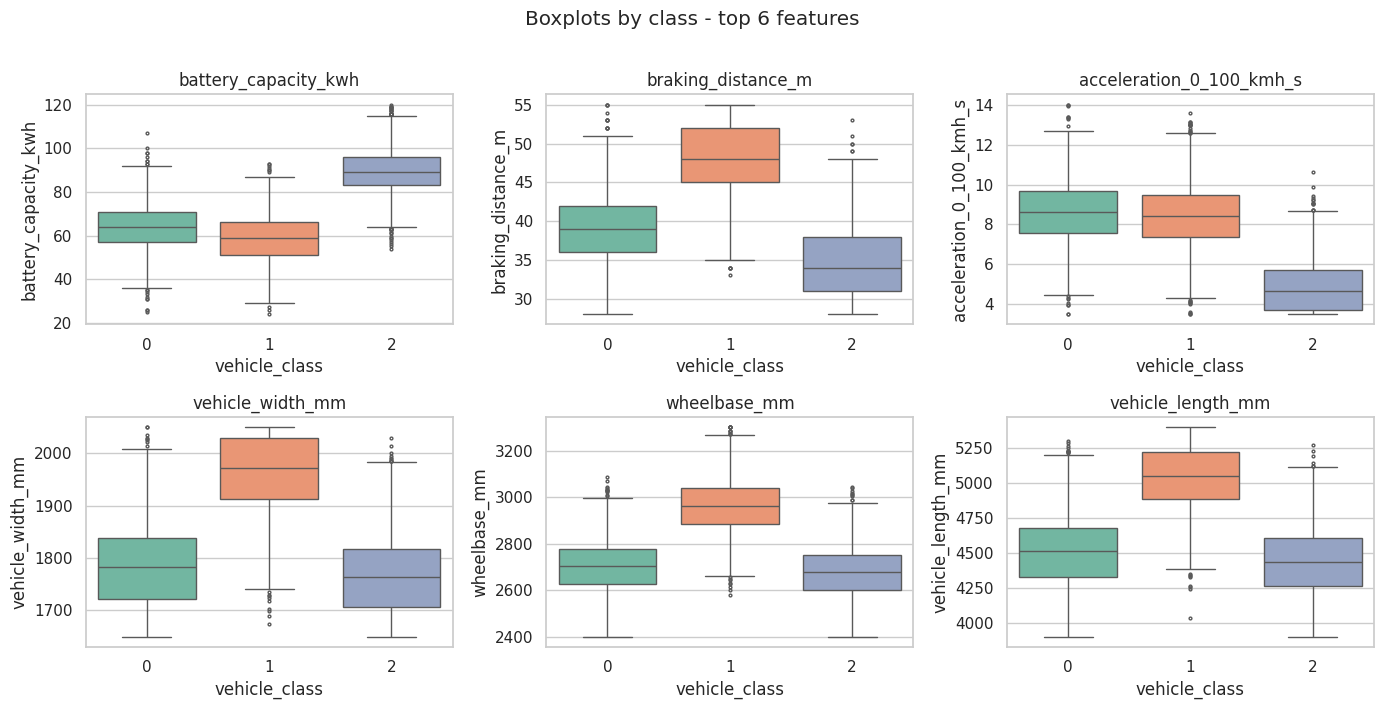

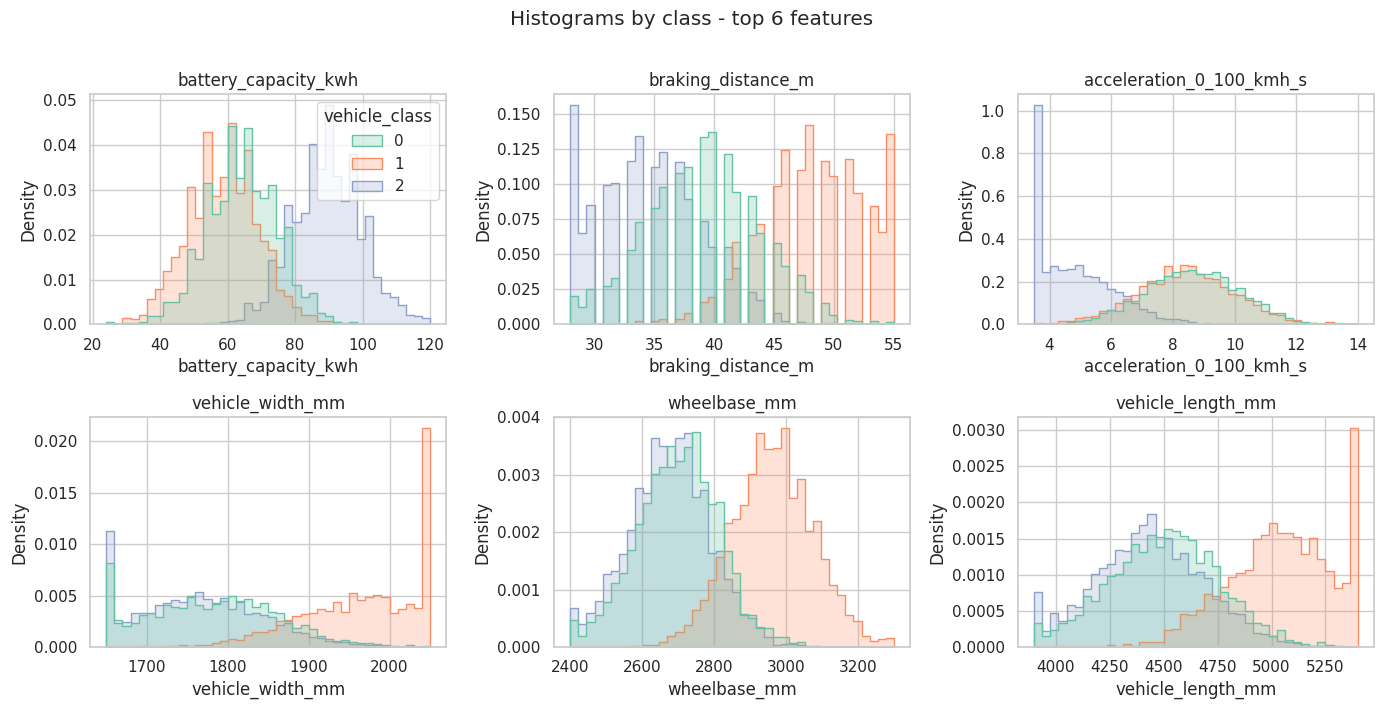

In [8]:
# --- Distributions by class for the most informative features -------------------------------------
palette = sns.color_palette("Set2", 3)

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, feat in zip(axes.ravel(), TOP):
    sns.boxplot(data=train, x=TARGET, y=feat, hue=TARGET, palette=palette, legend=False, fliersize=2, ax=ax)
    ax.set_title(feat)
fig.suptitle("Boxplots by class - top 6 features", y=1.01)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for i, (ax, feat) in enumerate(zip(axes.ravel(), TOP)):
    sns.histplot(data=train, x=feat, hue=TARGET, palette=palette, element="step", stat="density",
                 common_norm=False, bins=40, legend=(i == 0), ax=ax)
    ax.set_title(feat)
fig.suptitle("Histograms by class - top 6 features", y=1.01)
plt.tight_layout(); plt.show()

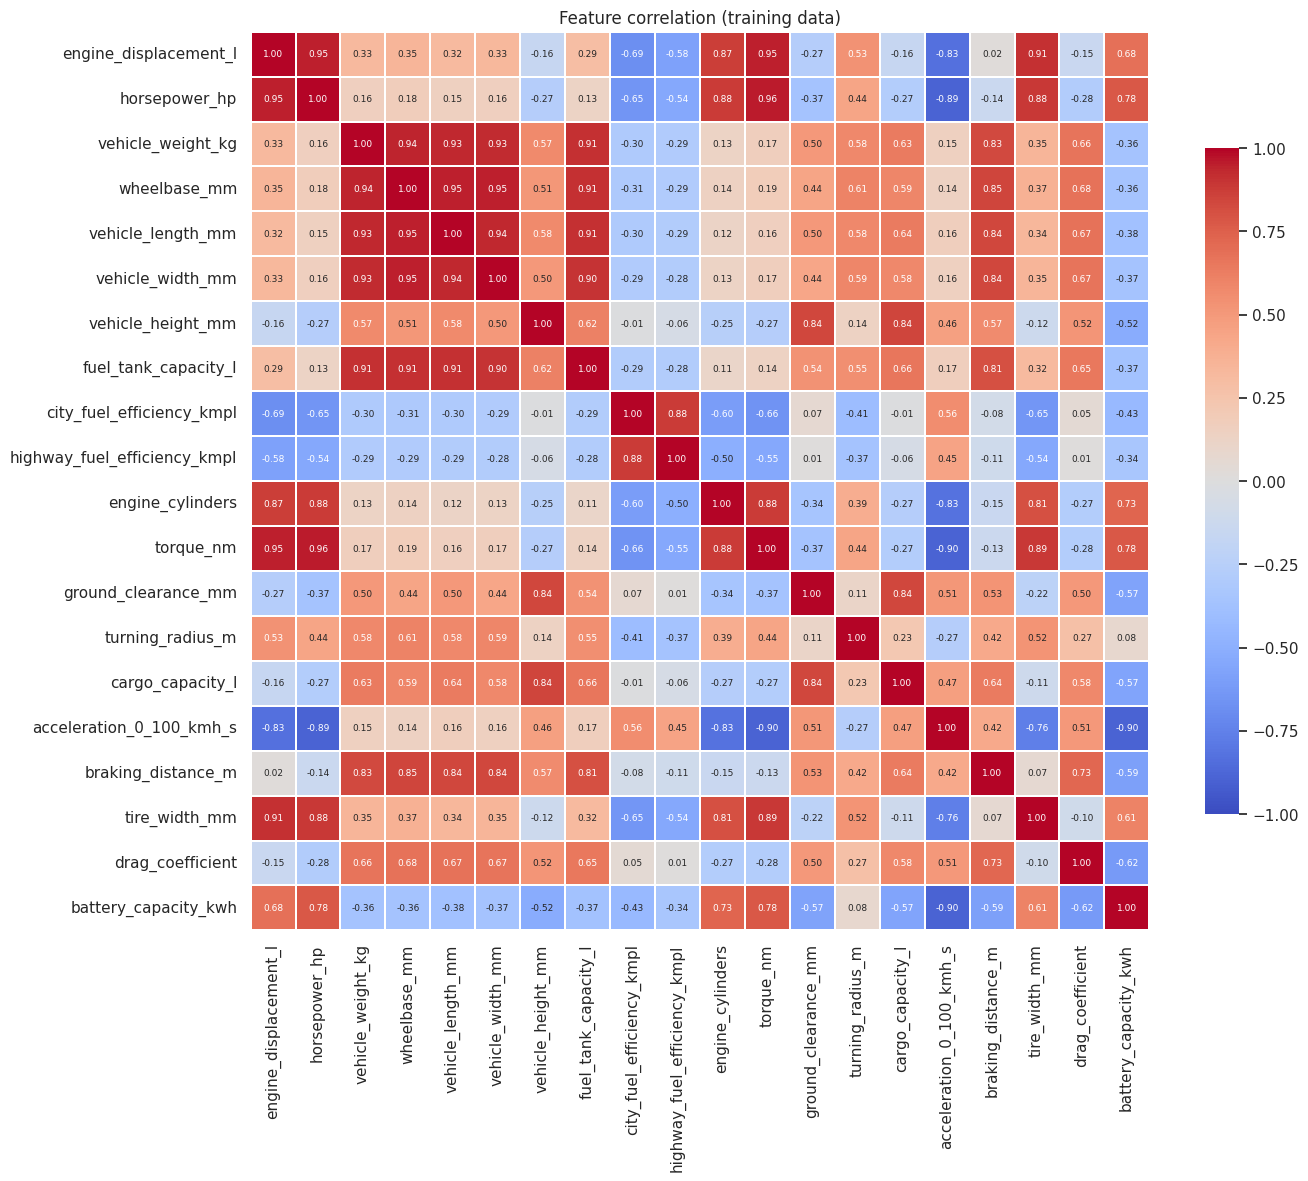

,feature_a,feature_b,r,|r|
0,horsepower_hp,torque_nm,0.959,0.959
1,engine_displacement_l,torque_nm,0.952,0.952
2,wheelbase_mm,vehicle_width_mm,0.952,0.952
3,engine_displacement_l,horsepower_hp,0.950,0.950
4,wheelbase_mm,vehicle_length_mm,0.949,0.949
5,vehicle_weight_kg,wheelbase_mm,0.945,0.945
6,vehicle_length_mm,vehicle_width_mm,0.937,0.937
7,vehicle_weight_kg,vehicle_length_mm,0.935,0.935
8,vehicle_weight_kg,vehicle_width_mm,0.929,0.929
9,vehicle_length_mm,fuel_tank_capacity_l,0.914,0.914


pairs with |r| > 0.9: 14 of 190


In [9]:
# --- Correlation heatmap ----------------------------------------------------------------------------
corr = X.corr()
fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(corr, annot=True, fmt=".2f", annot_kws={"size": 6.5}, cmap="coolwarm", vmin=-1, vmax=1,
            square=True, linewidths=0.3, cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("Feature correlation (training data)")
plt.tight_layout(); plt.show()

# Most correlated pairs
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().dropna().reset_index()
pairs.columns = ["feature_a", "feature_b", "r"]
pairs["|r|"] = pairs["r"].abs()
top_pairs = pairs.sort_values("|r|", ascending=False).head(10).reset_index(drop=True)
display(top_pairs.round(3))
print("pairs with |r| > 0.9:", int((pairs["|r|"] > 0.9).sum()), "of", len(pairs))

In [10]:
# --- Within-class correlation: the quantity that actually matters for Naive Bayes -------------------------
# NB assumes features are independent GIVEN the class, so check correlation inside each class (averaged).
within = sum(X[y == k].corr() for k in sorted(y.unique())) / y.nunique()

for a, b in [("horsepower_hp", "torque_nm"), ("wheelbase_mm", "vehicle_width_mm")]:
    print(f"{a:>16s} vs {b:<18s} overall r = {corr.loc[a, b]:.3f} | within-class r = {within.loc[a, b]:.3f}")

off = within.where(np.triu(np.ones(within.shape, dtype=bool), k=1)).stack().dropna().abs()
print(f"\nmean |within-class correlation| over all 190 pairs: {off.mean():.3f}")
print(f"pairs with within-class |r| > 0.8: {int((off > 0.8).sum())}")

   horsepower_hp vs torque_nm          overall r = 0.959 | within-class r = 0.930
    wheelbase_mm vs vehicle_width_mm   overall r = 0.952 | within-class r = 0.887

mean |within-class correlation| over all 190 pairs: 0.425
pairs with within-class |r| > 0.8: 22


**What the EDA shows**

* **Class structure.** Class 1 is the "big" class (heaviest, longest, widest, largest wheelbase and tank, longest braking distance, highest
  drag coefficient). Class 2 is the "powerful" class (highest horsepower, torque, cylinders and battery capacity, quickest acceleration,
  shortest braking distance, widest tyres). Class 0 is the low-power class (smallest engine, lowest horsepower and torque), with a body
  size close to class 2 and the best fuel economy. Size features separate class 1 from the others, power features separate class 2,
  and no single feature separates all three cleanly, so a combination of features is needed.
* **Heavy collinearity, in two blocks.** A "size" block (weight, wheelbase, length, width, tank capacity, braking distance) and a "power"
  block (displacement, horsepower, torque, cylinders, tyre width, acceleration, battery capacity). 14 of the 190 pairs have |r| > 0.9: `horsepower_hp` and `torque_nm` (r ≈ 0.96), `wheelbase_mm` and
  `vehicle_width_mm` (r ≈ 0.95), and also displacement, weight, length, tank size and tyre width. These are physically linked
  (bigger engine, more power and torque; bigger car, longer wheelbase, wider body).
* **The correlation survives inside each class** (printed above), so it is not just "classes differ, therefore features co-vary".

**Why this matters for Naive Bayes.** Gaussian NB multiplies per-feature likelihoods as if the features were independent given the class.
With horsepower and torque (or wheelbase and width) almost duplicating each other, the same evidence gets counted two or more times: the
posterior becomes over-confident and the class boundaries distort. The accuracy cost is limited (only the arg-max matters), but it should
make NB the weakest model here. For the other models the story differs: LDA and QDA model the full covariance (so they use the
correlation), ridge regularisation stabilises logistic regression under collinearity, and trees are indifferent to it (although
importance is split between near-duplicate features).

## 3. Preprocessing

All preprocessing lives **inside a scikit-learn `Pipeline`**, so inside every CV split the scaler (and any feature selector) is fitted on
the training fold only and merely applied to the validation fold. Fitting a scaler or selector on the full data before CV would leak
validation-fold information into training.

### 3.1 Missing values, outliers and train/test shift

,IQR outliers,% of rows,|z| > 4,skew,min,max
highway_fuel_efficiency_kmpl,49,0.65,0,0.03,9.00,24.07
turning_radius_m,39,0.52,0,-0.00,4.10,7.62
city_fuel_efficiency_kmpl,27,0.36,0,0.22,7.00,20.87
engine_displacement_l,18,0.24,0,-0.00,0.90,4.44
vehicle_weight_kg,13,0.17,0,0.34,1100.00,2600.00
vehicle_height_mm,8,0.11,0,0.09,1250.00,2050.00
wheelbase_mm,6,0.08,0,0.29,2400.00,3300.00
horsepower_hp,0,0.00,0,0.12,90.00,550.00
fuel_tank_capacity_l,0,0.00,0,0.18,35.00,90.00
vehicle_width_mm,0,0.00,0,0.25,1650.00,2050.00


rows with at least one IQR outlier: 1.80%
largest |z| in the data: 3.62


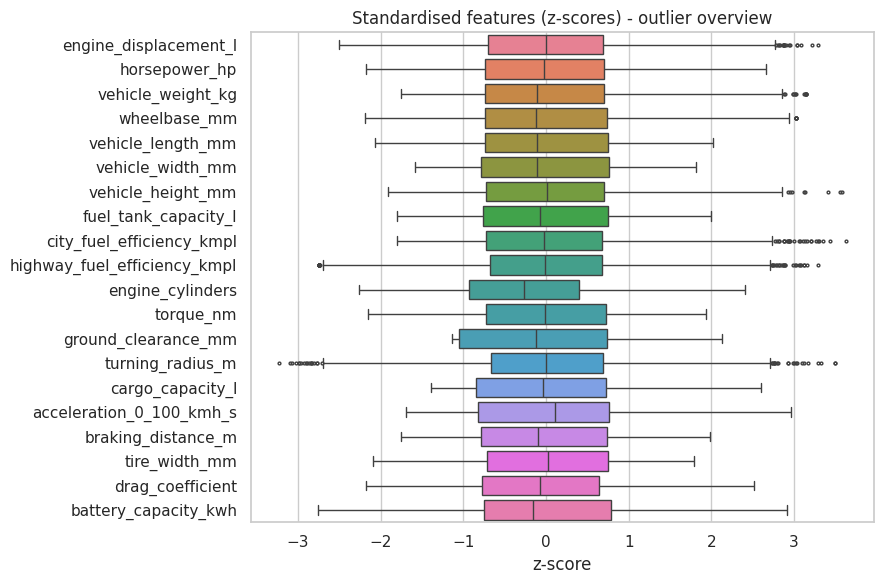


largest standardised train/test mean difference: 0.041 std (city_fuel_efficiency_kmpl)


In [11]:
# --- Outlier check (IQR rule and z-scores) -------------------------------------------------------
q1, q3 = X.quantile(0.25), X.quantile(0.75)
iqr = q3 - q1
iqr_flag = (X < q1 - 1.5 * iqr) | (X > q3 + 1.5 * iqr)
z = (X - X.mean()) / X.std()

outliers = pd.DataFrame({
    "IQR outliers": iqr_flag.sum(),
    "% of rows": (iqr_flag.mean() * 100).round(2),
    "|z| > 4": (z.abs() > 4).sum(),
    "skew": X.skew().round(2),
    "min": X.min(), "max": X.max(),
})
display(outliers.sort_values("IQR outliers", ascending=False))
print(f"rows with at least one IQR outlier: {iqr_flag.any(axis=1).mean() * 100:.2f}%")
print(f"largest |z| in the data: {z.abs().max().max():.2f}")

fig, ax = plt.subplots(figsize=(9, 6))
sns.boxplot(data=z, orient="h", fliersize=2, ax=ax)
ax.set_title("Standardised features (z-scores) - outlier overview"); ax.set_xlabel("z-score")
plt.tight_layout(); plt.show()

# Train/test shift check on the UNLABELLED features (no labels, no tuning): standardised mean difference
shift = ((X_test.mean() - X.mean()) / X.std()).abs()
print(f"\nlargest standardised train/test mean difference: {shift.max():.3f} std ({shift.idxmax()})")

**Missing values:** none in train or test, so no imputation is needed.

**Outliers:** the IQR rule flags at most about 0.65% of rows per feature (highway and city fuel efficiency, turning radius, displacement,
weight, height, wheelbase), about 1.8% of rows overall, and no |z| exceeds 4 (the largest is about 3.6). The skewness values are close to
zero, so these are just the tails of roughly symmetric distributions. All values lie in physically plausible, bounded ranges
(e.g. cylinders 3 to 10), so they look like genuine unusual vehicles, not data-entry errors. **Decision: keep all rows.** Removing
them would discard genuine class information, and the models below are not badly affected by values this mild.

**Train/test shift:** the test feature means are within a few hundredths of a standard deviation of the training means, so the test set
looks like it was drawn from the same distribution.

### 3.2 Scaling (inside the pipeline)

| Model | Scale? | Why |
|---|---|---|
| Logistic regression (L1/L2) | **Yes** | The penalty acts on coefficient size, so features in different units (mm vs litres) would be penalised unequally; `saga` also converges much better. |
| L1 selector (SelectFromModel) | **Yes** | Coefficient magnitudes must be comparable across features to decide what to drop. |
| LDA / QDA / Gaussian NB | **Yes (harmless)** | Predictions are scale-invariant, but QDA's `reg_param` shrinks towards an identity-like covariance and is only meaningful on a common scale; LDA shrinkage is also easier to interpret. |
| Decision tree | **No** | Splits depend only on feature order, so scaling cannot change the tree. |

### 3.3 Feature selection experiments

The features are highly redundant, so I try two selection strategies. Both are built **inside the CV pipeline**, so they are re-run on
each training fold, and the number of features (or the L1 strength) is tuned like any other hyper-parameter.

* **Forward selection** (`SequentialFeatureSelector`, wrapper method): start empty and greedily add the feature that most improves the
  inner 3-fold CV accuracy of an LDA classifier. Slow but directly optimises predictive performance.
* **L1-based selection** (`SelectFromModel` on an L1-penalised logistic regression, embedded method): keep the features with a non-zero
  coefficient. Fast; stronger penalty (smaller `C`) keeps fewer features.

The cell below only **illustrates** what each selector picks when fitted on the whole training set. These lists are not used for any score.

In [12]:
# --- Reusable pipeline pieces ---------------------------------------------------------------------
INNER_CV = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)   # for the forward-selection inner CV
CACHE = tempfile.mkdtemp()      # lets Pipeline cache fitted selectors, so tuning other params does not repeat the selection

def l1_logreg(C=1.0):
    """L1 (lasso) logistic regression. scikit-learn >= 1.8 replaced penalty='l1' by l1_ratio=1."""
    kw = dict(l1_ratio=1.0) if SK_VER >= (1, 8) else dict(penalty="l1")
    return LogisticRegression(solver="saga", C=C, max_iter=5000, random_state=SEED, **kw)

def forward_selector(k=8):
    return SequentialFeatureSelector(LinearDiscriminantAnalysis(solver="lsqr"), n_features_to_select=k,
                                     direction="forward", cv=INNER_CV, scoring="accuracy", n_jobs=-1)

def l1_selector(C=0.02):
    return SelectFromModel(l1_logreg(C))

def make_pipe(model, selector=None, scale=True):
    """scaler -> (optional selector) -> model, all fitted on the training fold only."""
    steps = []
    if scale:
        steps.append(("scale", StandardScaler()))
    if selector is not None:
        steps.append(("select", selector))
    steps.append(("model", model))
    return Pipeline(steps, memory=CACHE)

# --- Illustration on the full training set (NOT used for scoring) ------------------------------------
Z = pd.DataFrame(StandardScaler().fit_transform(X), columns=FEATURES)

fwd = forward_selector(8).fit(Z, y)
l1s = l1_selector(0.02).fit(Z, y)

sel_table = pd.DataFrame({"forward (k=8)": fwd.get_support(), "L1 (C=0.02)": l1s.get_support()}, index=FEATURES)
display(sel_table.replace({True: "kept", False: "-"}))
print("forward keeps", int(fwd.get_support().sum()), "features | L1 keeps", int(l1s.get_support().sum()), "features")

,forward (k=8),L1 (C=0.02)
engine_displacement_l,kept,-
horsepower_hp,kept,kept
vehicle_weight_kg,-,kept
wheelbase_mm,kept,kept
vehicle_length_mm,-,kept
vehicle_width_mm,-,kept
vehicle_height_mm,kept,kept
fuel_tank_capacity_l,-,-
city_fuel_efficiency_kmpl,-,-
highway_fuel_efficiency_kmpl,kept,kept


forward keeps 8 features | L1 keeps 12 features


## 4. Validation strategy

* **Repeated stratified 5-fold CV** (5 folds x 3 repeats = 15 validation scores per configuration). Stratification keeps the class mix in every fold.
* The splitter is created **once** with a fixed `random_state`, and every model, grid search and comparison uses that same object, so every
  model is scored on **exactly the same folds**, making scores directly comparable (this is also what makes the paired comparison in Section 6 valid).
* **Reported:** mean and standard deviation of accuracy over the 15 folds. The std is the fold-to-fold spread (a spread, not a standard
  error of the mean).
* **Hyper-parameters** are tuned with `GridSearchCV` on this same CV. The best score is therefore slightly optimistic (the winner of
  many configurations enjoys some selection luck); Section 6 includes a nested-CV check to size that effect.
* The **confusion matrix** needs the best model, which is only known after Section 6. The helper is defined here and used in Section 7.

In [13]:
# --- The CV splitter shared by every model ----------------------------------------------------------
N_SPLITS, N_REPEATS = 5, 3
cv = RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=SEED)

# Proof that the folds are identical every time they are generated
folds_a = [tuple(va) for _, va in cv.split(X, y)]
folds_b = [tuple(va) for _, va in cv.split(X, y)]
print("same folds on every call:", folds_a == folds_b, "| number of validation folds:", len(folds_a))

# Registry of results and specs, filled in Section 5
RESULTS, SPECS = {}, {}

def tune(name, pipe, grid):
    """Grid-search `pipe` over `grid` with the shared CV, store the best configuration's fold scores."""
    gs = GridSearchCV(pipe, grid, cv=cv, scoring="accuracy", n_jobs=-1, refit=True)
    gs.fit(X, y)
    i = gs.best_index_
    scores = np.array([gs.cv_results_[f"split{k}_test_score"][i] for k in range(N_SPLITS * N_REPEATS)])
    clean = {k: (v.item() if isinstance(v, np.generic) else v) for k, v in gs.best_params_.items()}   # plain Python numbers
    RESULTS[name] = dict(mean=scores.mean(), std=scores.std(ddof=1), fold_scores=scores,
                         best_params=clean, search=gs)
    SPECS[name] = (pipe, grid)
    print(f"{name}\n  best params : {clean}\n  CV accuracy : {scores.mean():.4f} +/- {scores.std(ddof=1):.4f}"
          f"  ({len(gs.cv_results_['params'])} configurations x {len(scores)} folds)")
    return gs

def plot_param_curve(gs, param, title, ax=None):
    """CV accuracy (mean +/- std over folds) vs one hyper-parameter; other params at their best value."""
    res = pd.DataFrame(gs.cv_results_)
    col = f"param_{param}"
    best_rows = res.loc[res.groupby(res[col].astype(str), sort=False)["mean_test_score"].idxmax()]
    ax = ax or plt.subplots(figsize=(7, 3.6))[1]
    xs = np.arange(len(best_rows))
    ax.errorbar(xs, best_rows["mean_test_score"], yerr=best_rows["std_test_score"], marker="o", capsize=3)
    ax.set_xticks(xs); ax.set_xticklabels([str(v) for v in best_rows[col]], rotation=45, ha="right")
    ax.set_xlabel(param); ax.set_ylabel("CV accuracy"); ax.set_title(title)
    return ax

def cv_confusion(estimator, title):
    """Out-of-fold predictions using the first repeat of the shared CV (5 folds = a full partition of the data)."""
    pred = np.empty(len(y), dtype=int)
    for tr_idx, va_idx in itertools.islice(cv.split(X, y), N_SPLITS):
        pred[va_idx] = clone(estimator).fit(X.iloc[tr_idx], y.iloc[tr_idx]).predict(X.iloc[va_idx])
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    ConfusionMatrixDisplay(confusion_matrix(y, pred)).plot(ax=axes[0], cmap="Blues", colorbar=False)
    axes[0].set_title("counts"); axes[0].grid(False)
    ConfusionMatrixDisplay(confusion_matrix(y, pred, normalize="true"), display_labels=[0, 1, 2]).plot(
        ax=axes[1], cmap="Blues", colorbar=False, values_format=".2f")
    axes[1].set_title("row-normalised (recall)"); axes[1].grid(False)
    fig.suptitle(title); plt.tight_layout(); plt.show()
    print(pd.DataFrame(confusion_matrix(y, pred), index=[f"true {c}" for c in range(3)],
                       columns=[f"pred {c}" for c in range(3)]).to_string(), "\n")
    print(classification_report(y, pred, digits=3))
    return pred

same folds on every call: True | number of validation folds: 15


### Why the duplicate removal matters (quantified)

Same models, same CV, once on the raw 10,000 rows and once on the 7,500 unique rows. Smooth models such as LDA and logistic regression are
almost unaffected, but an unpruned decision tree, which can memorise its training rows, looks much better on the raw data purely
because it has already seen the twin of many validation rows.

In [14]:
# --- Leakage demonstration: raw (with duplicates) vs de-duplicated ----------------------------------------
def cv_acc(estimator, data):
    s = cross_val_score(estimator, data[FEATURES], data[TARGET], cv=cv, n_jobs=-1)
    return f"{s.mean():.4f} +/- {s.std(ddof=1):.4f}"

train_unique = train_raw.drop_duplicates(subset=FEATURES, keep="first")
demo = {
    "Unpruned decision tree": DecisionTreeClassifier(random_state=SEED),
    "Depth-6 decision tree": DecisionTreeClassifier(max_depth=6, random_state=SEED),
    "LDA": make_pipe(LinearDiscriminantAnalysis()),
    "Logistic regression (ridge, C=0.1)": make_pipe(LogisticRegression(C=0.1, max_iter=5000, random_state=SEED)),
}
leak = pd.DataFrame({name: {"raw 10,000 rows (twins can leak across folds)": cv_acc(m, train_raw),
                            "7,500 unique rows (honest)": cv_acc(m, train_unique)} for name, m in demo.items()}).T
display(leak)

,"raw 10,000 rows (twins can leak across folds)","7,500 unique rows (honest)"
Unpruned decision tree,0.8967 +/- 0.0061,0.8248 +/- 0.0105
Depth-6 decision tree,0.8725 +/- 0.0060,0.8622 +/- 0.0070
LDA,0.8935 +/- 0.0048,0.8922 +/- 0.0068
"Logistic regression (ridge, C=0.1)",0.8950 +/- 0.0062,0.8943 +/- 0.0077


## 5. Models and tuning

Each model is tuned with `GridSearchCV` on the shared CV. Pipelines are `scaler -> [selector] -> model`, except for trees
(no scaling needed). The best configuration's mean ± std accuracy is recorded in `RESULTS`.

### 5.1 Logistic regression: ridge (L2)

Multinomial logistic regression with an L2 penalty. `C` is the **inverse** regularisation strength (small `C` = strong shrinkage).

Logistic regression - ridge (L2)
  best params : {'model__C': 0.1}
  CV accuracy : 0.8943 +/- 0.0077  (13 configurations x 15 folds)


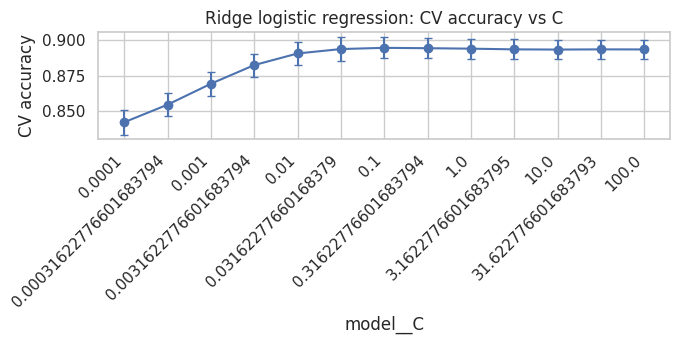

In [15]:
# --- 5.1 Logistic regression, ridge ----------------------------------------------------------------------------
gs_ridge = tune(
    "Logistic regression - ridge (L2)",
    make_pipe(LogisticRegression(max_iter=5000, random_state=SEED)),      # default penalty is L2
    {"model__C": np.logspace(-4, 2, 13)},
)
plot_param_curve(gs_ridge, "model__C", "Ridge logistic regression: CV accuracy vs C")
plt.tight_layout(); plt.show()

### 5.2 Logistic regression: lasso (L1)

The L1 penalty drives some coefficients exactly to zero, which performs feature selection as a by-product. For multinomial regression a
feature is "zeroed out" only if its coefficient is zero for **all three** classes. I tune `C`, then inspect (a) the best `C` and (b) the
**sparsest model within one standard error of the best** (one-standard-error rule), the usual way to read lasso when the accuracy
curve is flat.

Logistic regression - lasso (L1)
  best params : {'model__C': 0.5}
  CV accuracy : 0.8932 +/- 0.0071  (10 configurations x 15 folds)


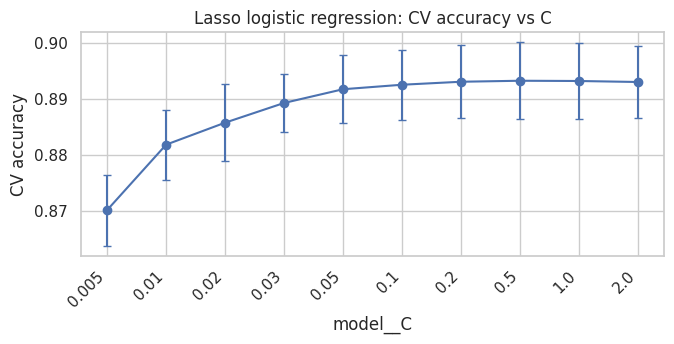

In [16]:
# --- 5.2 Logistic regression, lasso ------------------------------------------------------------------------------------
gs_lasso = tune(
    "Logistic regression - lasso (L1)",
    make_pipe(l1_logreg()),
    {"model__C": [0.005, 0.01, 0.02, 0.03, 0.05, 0.1, 0.2, 0.5, 1, 2]},
)
plot_param_curve(gs_lasso, "model__C", "Lasso logistic regression: CV accuracy vs C")
plt.tight_layout(); plt.show()

best C = 0.5 | one-SE threshold = 0.8900 | smallest C within one SE = 0.05

best C: C = 0.5 -> 0 of 20 features have all-zero coefficients
   zeroed out: none

one-SE C: C = 0.05 -> 1 of 20 features have all-zero coefficients
   zeroed out: ['cargo_capacity_l']


,class 0,class 1,class 2,zeroed out
engine_displacement_l,0.000,0.000,0.201,False
horsepower_hp,0.000,-0.122,0.500,False
vehicle_weight_kg,0.000,0.339,-0.005,False
wheelbase_mm,0.000,1.720,-0.911,False
vehicle_length_mm,0.000,0.815,-0.097,False
vehicle_width_mm,0.000,0.853,0.000,False
vehicle_height_mm,0.578,-0.237,0.000,False
fuel_tank_capacity_l,0.000,0.120,0.000,False
city_fuel_efficiency_kmpl,0.000,-0.148,0.089,False
highway_fuel_efficiency_kmpl,0.000,-0.016,0.473,False


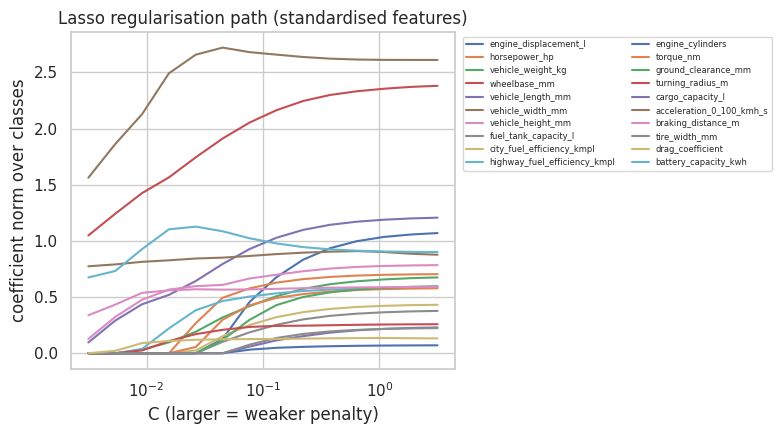

In [17]:
# --- Which features does the lasso zero out? ----------------------------------------------------------------------------------
res = pd.DataFrame(gs_lasso.cv_results_)
best_mean, best_std = RESULTS["Logistic regression - lasso (L1)"]["mean"], RESULTS["Logistic regression - lasso (L1)"]["std"]
threshold = best_mean - best_std / np.sqrt(N_SPLITS)                 # one-standard-error rule
sparse_C = res.loc[res["mean_test_score"] >= threshold, "param_model__C"].astype(float).min()
best_C = gs_lasso.best_params_["model__C"]
print(f"best C = {best_C} | one-SE threshold = {threshold:.4f} | smallest C within one SE = {sparse_C}")

Zs = StandardScaler().fit_transform(X)            # illustration fit on all training data
coef_tables = {}
for label, C in [("best C", best_C), ("one-SE C", sparse_C)]:
    m = l1_logreg(C).fit(Zs, y)
    coef = pd.DataFrame(m.coef_.T, index=FEATURES, columns=[f"class {k}" for k in m.classes_])
    coef["zeroed out"] = (coef.abs().sum(axis=1) == 0)
    coef_tables[label] = coef
    print(f"\n{label}: C = {C} -> {int(coef['zeroed out'].sum())} of {len(FEATURES)} features have all-zero coefficients")
    zeroed = coef.index[coef["zeroed out"]].tolist()
    print("   zeroed out:", zeroed if zeroed else "none")

display(coef_tables["one-SE C"].round(3))

# Regularisation path: size of each feature's coefficients (L2 norm over the 3 classes) as C grows
Cs = np.logspace(-2.5, 0.5, 14)
path = np.array([np.linalg.norm(l1_logreg(C).fit(Zs, y).coef_, axis=0) for C in Cs])
fig, ax = plt.subplots(figsize=(8, 4.5))
for j, f in enumerate(FEATURES):
    ax.plot(Cs, path[:, j], label=f)
ax.set_xscale("log"); ax.set_xlabel("C (larger = weaker penalty)"); ax.set_ylabel("coefficient norm over classes")
ax.set_title("Lasso regularisation path (standardised features)")
ax.legend(fontsize=6, ncol=2, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout(); plt.show()

### 5.3 Linear Discriminant Analysis (LDA)

LDA fits one Gaussian per class with a **shared covariance matrix**, giving linear boundaries. With 20 correlated features, the pooled
covariance can be noisy, so I tune the **shrinkage** of the covariance (`solver='lsqr'`; `None` = no shrinkage, `'auto'` = Ledoit-Wolf
estimate, or a fixed value in [0, 1]). I run LDA on (a) all features, (b) the L1-selected subset and (c) the forward-selected subset,
with the selection redone inside each training fold. Note that the selector strength is tuned too, so if keeping every feature is best, the
"selected subset" can end up being the full feature set; the trade-off table printed in the L1 cell shows what sparser choices cost.

LDA - all features
  best params : {'model__shrinkage': 0.1}
  CV accuracy : 0.8939 +/- 0.0083  (10 configurations x 15 folds)


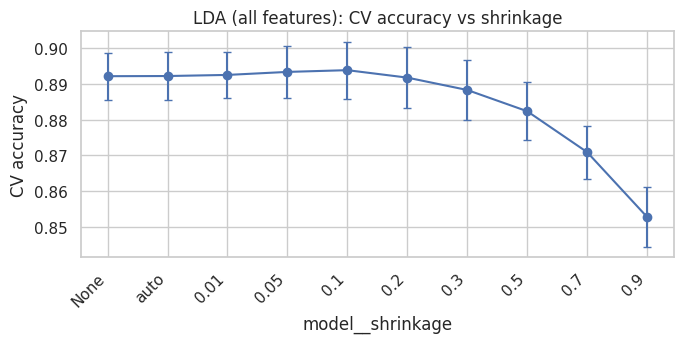

In [18]:
# --- 5.3a LDA on all features -----------------------------------------------------------------------------------------------------------
SHRINK = [None, "auto", 0.01, 0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 0.9]
gs_lda = tune(
    "LDA - all features",
    make_pipe(LinearDiscriminantAnalysis(solver="lsqr")),
    {"model__shrinkage": SHRINK},
)
plot_param_curve(gs_lda, "model__shrinkage", "LDA (all features): CV accuracy vs shrinkage")
plt.tight_layout(); plt.show()

LDA - L1-selected subset
  best params : {'model__shrinkage': 0.1, 'select__estimator__C': 0.1}
  CV accuracy : 0.8939 +/- 0.0083  (16 configurations x 15 folds)


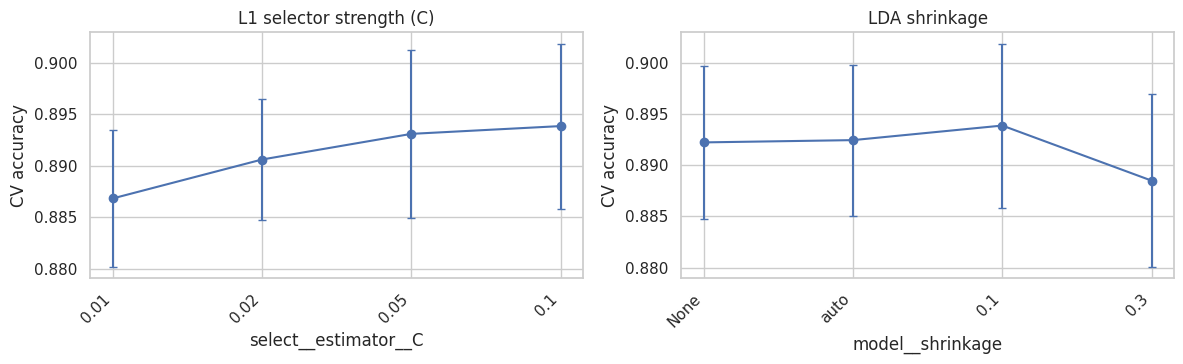

L1 subset at the best selector strength: 20 of 20 features


,selector C,features kept (full-data fit),best CV accuracy
0,0.01,11,0.8868
1,0.02,12,0.8906
2,0.05,19,0.8931
3,0.10,20,0.8939


In [19]:
# --- 5.3b LDA on an L1-selected subset (selection inside each fold) ------------------------------------------------------
gs_lda_l1 = tune(
    "LDA - L1-selected subset",
    make_pipe(LinearDiscriminantAnalysis(solver="lsqr"), selector=l1_selector()),
    {"select__estimator__C": [0.01, 0.02, 0.05, 0.1], "model__shrinkage": [None, "auto", 0.1, 0.3]},
)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
plot_param_curve(gs_lda_l1, "select__estimator__C", "L1 selector strength (C)", ax=axes[0])
plot_param_curve(gs_lda_l1, "model__shrinkage", "LDA shrinkage", ax=axes[1])
plt.tight_layout(); plt.show()

# Illustration: features kept by the best configuration when fitted on all training data
best_l1 = clone(gs_lda_l1.best_estimator_).fit(X, y)
kept = np.array(FEATURES)[best_l1.named_steps["select"].get_support()].tolist()
n_l1_kept = len(kept)
print(f"L1 subset at the best selector strength: {n_l1_kept} of {len(FEATURES)} features")
if n_l1_kept < len(FEATURES):
    print("kept:", kept)

# Trade-off: how many features does each selector strength keep (fit on all training data), and what CV accuracy results?
res_l1 = pd.DataFrame(gs_lda_l1.cv_results_)
tradeoff = []
for C in sorted(res_l1["param_select__estimator__C"].unique()):
    n_kept = int(l1_selector(C).fit(Zs, y).get_support().sum())
    best_at_C = res_l1.loc[res_l1["param_select__estimator__C"] == C, "mean_test_score"].max()
    tradeoff.append({"selector C": C, "features kept (full-data fit)": n_kept, "best CV accuracy": round(best_at_C, 4)})
L1_TRADEOFF = pd.DataFrame(tradeoff)
display(L1_TRADEOFF)

LDA - forward-selected subset
  best params : {'model__shrinkage': None, 'select__n_features_to_select': 10}
  CV accuracy : 0.8890 +/- 0.0070  (15 configurations x 15 folds)


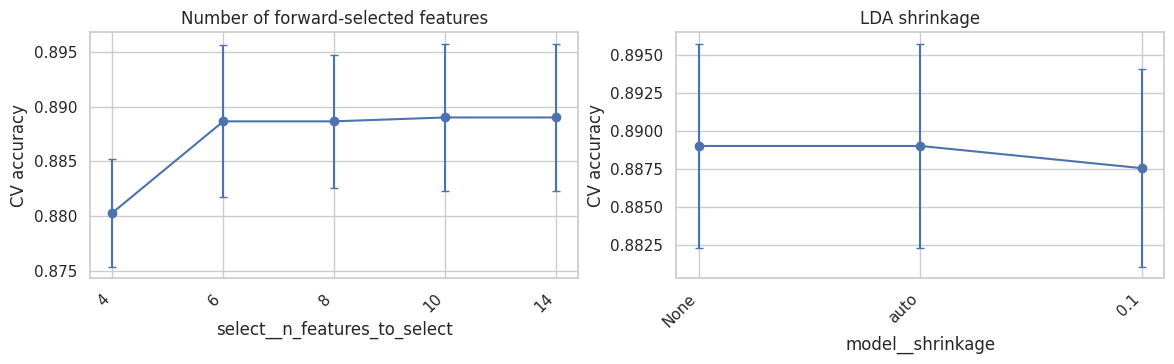

Forward subset (10 features): ['engine_displacement_l', 'horsepower_hp', 'wheelbase_mm', 'vehicle_height_mm', 'highway_fuel_efficiency_kmpl', 'torque_nm', 'turning_radius_m', 'acceleration_0_100_kmh_s', 'braking_distance_m', 'battery_capacity_kwh']


In [20]:
# --- 5.3c LDA on a forward-selected subset (selection inside each fold; this cell is the slowest one) ----------------------
gs_lda_fwd = tune(
    "LDA - forward-selected subset",
    make_pipe(LinearDiscriminantAnalysis(solver="lsqr"), selector=forward_selector()),
    {"select__n_features_to_select": [4, 6, 8, 10, 14], "model__shrinkage": [None, "auto", 0.1]},
)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
plot_param_curve(gs_lda_fwd, "select__n_features_to_select", "Number of forward-selected features", ax=axes[0])
plot_param_curve(gs_lda_fwd, "model__shrinkage", "LDA shrinkage", ax=axes[1])
plt.tight_layout(); plt.show()

best_fwd = clone(gs_lda_fwd.best_estimator_).fit(X, y)
kept = np.array(FEATURES)[best_fwd.named_steps["select"].get_support()].tolist()
print(f"Forward subset ({len(kept)} features):", kept)

### 5.4 Quadratic Discriminant Analysis (QDA)

QDA gives each class its **own covariance matrix** (quadratic boundaries). That is more flexible than LDA but needs 3 x 210 covariance
parameters instead of 210, and with near-collinear features the class covariances are close to singular. `reg_param` shrinks each class
covariance towards the identity (on standardised features), stabilising the estimate. `reg_param = 0` is plain QDA.

QDA
  best params : {'model__reg_param': 0.1}
  CV accuracy : 0.8895 +/- 0.0072  (10 configurations x 15 folds)


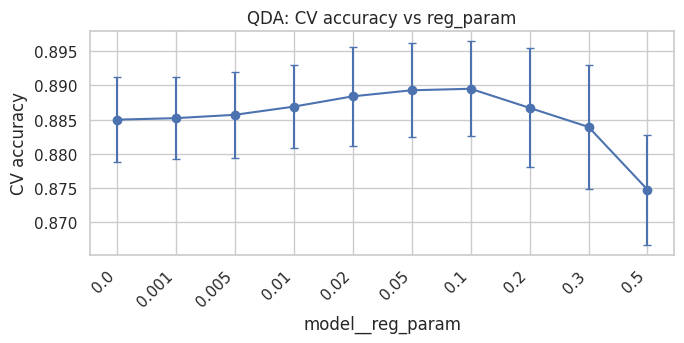

In [21]:
# --- 5.4 QDA -------------------------------------------------------------------------------------------------------------------------
gs_qda = tune(
    "QDA",
    make_pipe(QuadraticDiscriminantAnalysis()),
    {"model__reg_param": [0, 0.001, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.3, 0.5]},
)
plot_param_curve(gs_qda, "model__reg_param", "QDA: CV accuracy vs reg_param")
plt.tight_layout(); plt.show()

### 5.5 Decision tree

Tuned over `criterion` (gini vs entropy), `max_depth`, `min_samples_leaf` and the cost-complexity pruning strength `ccp_alpha`.
No scaler is used. A fully grown tree overfits (it can memorise the training rows), so the interesting question is how much
regularisation (depth limit, larger leaves, pruning) helps.

Decision tree
  best params : {'ccp_alpha': 0.0005, 'criterion': 'gini', 'max_depth': 7, 'min_samples_leaf': 1}
  CV accuracy : 0.8625 +/- 0.0078  (160 configurations x 15 folds)


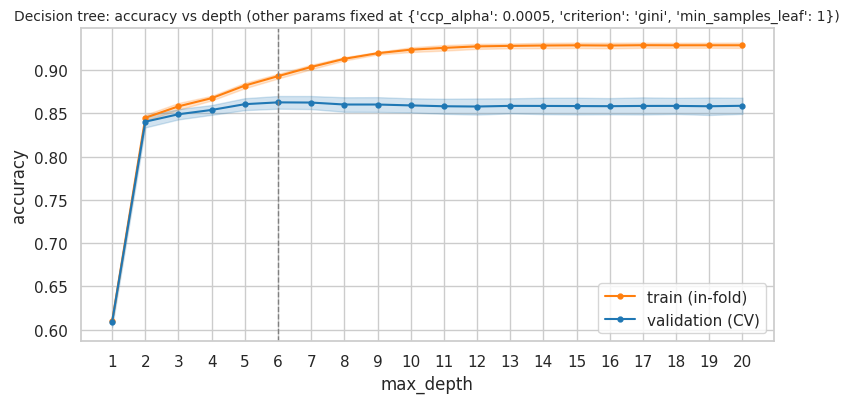

depth with the best validation accuracy: 6 | best mean validation accuracy: 0.8627


In [22]:
# --- 5.5 Decision tree (grid search) ------------------------------------------------------------------------------------------------------
gs_tree = tune(
    "Decision tree",
    DecisionTreeClassifier(random_state=SEED),
    {
        "criterion": ["gini", "entropy"],
        "max_depth": [3, 5, 7, 10, None],
        "min_samples_leaf": [1, 5, 15, 40],
        "ccp_alpha": [0.0, 0.0005, 0.002, 0.005],
    },
)

# Validation accuracy vs depth, all other hyper-parameters held at their best values
best_p = {k: v for k, v in gs_tree.best_params_.items() if k != "max_depth"}
depths = list(range(1, 21))
train_sc, val_sc = validation_curve(DecisionTreeClassifier(random_state=SEED, **best_p), X, y,
                                    param_name="max_depth", param_range=depths, cv=cv,
                                    scoring="accuracy", n_jobs=-1)
fig, ax = plt.subplots(figsize=(8, 4.2))
for sc, lab, col in [(train_sc, "train (in-fold)", "tab:orange"), (val_sc, "validation (CV)", "tab:blue")]:
    ax.plot(depths, sc.mean(axis=1), marker="o", ms=3.5, label=lab, color=col)
    ax.fill_between(depths, sc.mean(axis=1) - sc.std(axis=1), sc.mean(axis=1) + sc.std(axis=1), alpha=0.2, color=col)
ax.axvline(depths[int(val_sc.mean(axis=1).argmax())], ls="--", color="gray", lw=1)
ax.set_xlabel("max_depth"); ax.set_ylabel("accuracy"); ax.set_xticks(depths)
ax.set_title(f"Decision tree: accuracy vs depth (other params fixed at {best_p})", fontsize=10); ax.legend()
plt.tight_layout(); plt.show()
print("depth with the best validation accuracy:", depths[int(val_sc.mean(axis=1).argmax())],
      "| best mean validation accuracy:", round(val_sc.mean(axis=1).max(), 4))

fitted tree: depth = 7 | leaves = 63


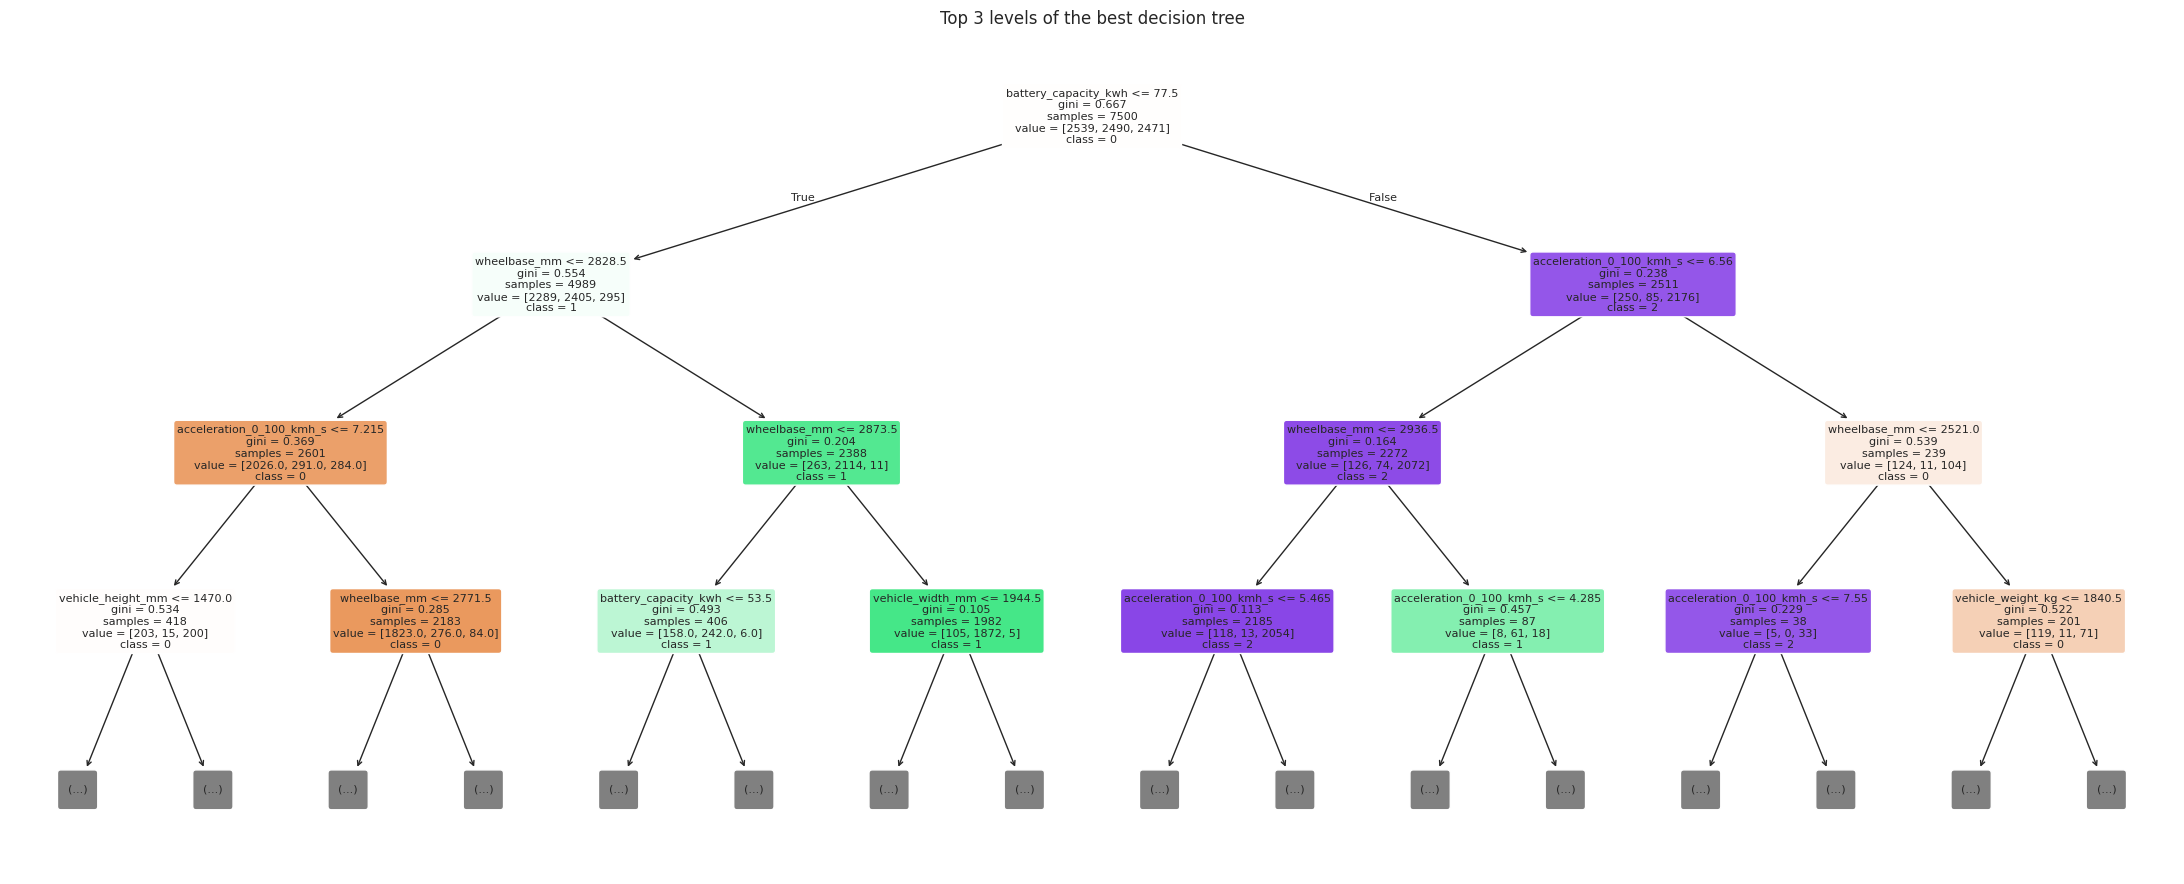

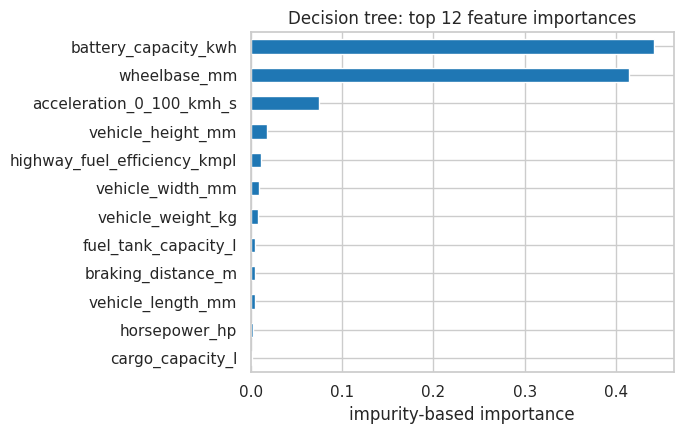

In [23]:
# --- Tree structure and feature importances (tree refit on ALL training data by GridSearchCV) -----------------------------------------------------
tree = gs_tree.best_estimator_
print("fitted tree: depth =", tree.get_depth(), "| leaves =", tree.get_n_leaves())

fig, ax = plt.subplots(figsize=(22, 9))
plot_tree(tree, max_depth=3, feature_names=FEATURES, class_names=[str(c) for c in tree.classes_],
          filled=True, rounded=True, fontsize=8, ax=ax)
ax.set_title("Top 3 levels of the best decision tree")
plt.tight_layout(); plt.show()

imp = pd.Series(tree.feature_importances_, index=FEATURES).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(7, 4.5))
imp.head(12)[::-1].plot.barh(ax=ax, color="tab:blue")
ax.set_xlabel("impurity-based importance"); ax.set_title("Decision tree: top 12 feature importances")
plt.tight_layout(); plt.show()

### 5.6 Gaussian Naive Bayes (baseline)

One Gaussian per feature per class, with features assumed **independent given the class**. It has almost no tuning knob
(`var_smoothing` adds a small amount of variance for stability), so this is a baseline. As an extra experiment I also run NB on the
forward-selected subset, which tests the idea from Section 2 that dropping redundant features should help NB.

In [24]:
# --- 5.6 Gaussian NB ------------------------------------------------------------------------------------------------------------------------------
gs_nb = tune(
    "Gaussian Naive Bayes (baseline)",
    make_pipe(GaussianNB()),
    {"model__var_smoothing": np.logspace(-9, 0, 10)},
)

# Extra experiment: NB on a forward-selected subset (selection inside each fold, using LDA as the selector's estimator)
gs_nb_fwd = tune(
    "Gaussian NB - forward-selected subset (extra)",
    make_pipe(GaussianNB(), selector=forward_selector()),
    {"select__n_features_to_select": [2, 3, 4, 5, 8, 12]},
)
print("features kept by the best NB subset (fit on all training data):",
      np.array(FEATURES)[clone(gs_nb_fwd.best_estimator_).fit(X, y).named_steps["select"].get_support()].tolist())

Gaussian Naive Bayes (baseline)
  best params : {'model__var_smoothing': 1e-09}
  CV accuracy : 0.8468 +/- 0.0082  (10 configurations x 15 folds)
Gaussian NB - forward-selected subset (extra)
  best params : {'select__n_features_to_select': 3}
  CV accuracy : 0.8640 +/- 0.0082  (6 configurations x 15 folds)
features kept by the best NB subset (fit on all training data): ['wheelbase_mm', 'acceleration_0_100_kmh_s', 'braking_distance_m']


In [25]:
# --- Evidence for the 'double counting' argument: confidence vs accuracy (first CV repeat, out-of-fold) --------------------------------------------
def oof_confidence(estimator):
    conf, correct = [], []
    for tr_idx, va_idx in itertools.islice(cv.split(X, y), N_SPLITS):
        m = clone(estimator).fit(X.iloc[tr_idx], y.iloc[tr_idx])
        proba = m.predict_proba(X.iloc[va_idx])
        conf.append(proba.max(axis=1)); correct.append(m.classes_[proba.argmax(axis=1)] == y.iloc[va_idx].values)
    conf, correct = np.concatenate(conf), np.concatenate(correct)
    return conf.mean(), correct.mean()

calib = pd.DataFrame({
    "Gaussian NB": oof_confidence(gs_nb.best_estimator_),
    "LDA": oof_confidence(gs_lda.best_estimator_),
    "Ridge logistic": oof_confidence(gs_ridge.best_estimator_),
}, index=["mean max predicted probability", "accuracy"]).T
calib["over-confidence"] = calib.iloc[:, 0] - calib.iloc[:, 1]
display(calib.round(3))

,mean max predicted probability,accuracy,over-confidence
Gaussian NB,0.977,0.847,0.129
LDA,0.900,0.894,0.007
Ridge logistic,0.885,0.894,-0.009


## 6. Results

In [26]:
# --- Results table (format: Model | Best Score Achieved | Key observation) -------------------------------------------------
def bp(name, key):   # convenience: read a best hyper-parameter
    return RESULTS[name]["best_params"][key]

n_zero_best = int(coef_tables["best C"]["zeroed out"].sum())
zeroed_1se = coef_tables["one-SE C"].index[coef_tables["one-SE C"]["zeroed out"]].tolist()
nb_conf, nb_acc = calib.loc["Gaussian NB", "mean max predicted probability"], calib.loc["Gaussian NB", "accuracy"]
nb_gain = RESULTS["Gaussian NB - forward-selected subset (extra)"]["mean"] - RESULTS["Gaussian Naive Bayes (baseline)"]["mean"]
tree_k = bp("Decision tree", "max_depth")

OBS = {
    "Logistic regression - ridge (L2)":
        f"Best C = {bp('Logistic regression - ridge (L2)', 'model__C'):.3g}. Accuracy is flat for C >= 0.03 and only drops under very strong shrinkage; "
        "tied with LDA and lasso.",
    "Logistic regression - lasso (L1)":
        f"Best C = {bp('Logistic regression - lasso (L1)', 'model__C'):.3g} zeroes out {n_zero_best} of 20 features; at the sparser one-SE C = {sparse_C:g} "
        f"only {', '.join(zeroed_1se) if zeroed_1se else 'no feature'} is fully zeroed. Same accuracy as ridge within noise.",
    "LDA - all features":
        f"Best shrinkage = {bp('LDA - all features', 'model__shrinkage')}. Mild shrinkage helps slightly over none, heavy shrinkage hurts; "
        "matches ridge logistic regression.",
    "LDA - L1-selected subset":
        f"Selector C = {bp('LDA - L1-selected subset', 'select__estimator__C')} keeps {n_l1_kept} of 20 features, so it equals full LDA; "
        "sparser selections score lower (see trade-off table).",
    "LDA - forward-selected subset":
        f"Best k = {bp('LDA - forward-selected subset', 'select__n_features_to_select')} of 20, shrinkage = {bp('LDA - forward-selected subset', 'model__shrinkage')}. "
        "Dropping features did not help: the redundant-looking features still add some class information.",
    "QDA":
        f"Best reg_param = {bp('QDA', 'model__reg_param')}. Needs regularisation (plain QDA is lower) and still does not beat LDA, "
        "so class-specific covariances add variance without extra signal.",
    "Decision tree":
        f"{bp('Decision tree', 'criterion')}, max_depth = {tree_k}, min_samples_leaf = {bp('Decision tree', 'min_samples_leaf')}, "
        f"ccp_alpha = {bp('Decision tree', 'ccp_alpha')}. Overfits (train far above validation) and trails the linear models by about 3 points: "
        "axis-aligned splits approximate oblique boundaries poorly.",
    "Gaussian Naive Bayes (baseline)":
        f"Weakest model. Over-confident: mean predicted probability {nb_conf:.2f} vs accuracy {nb_acc:.2f}, because correlated features "
        "are counted as independent evidence.",
    "Gaussian NB - forward-selected subset (extra)":
        f"k = {bp('Gaussian NB - forward-selected subset (extra)', 'select__n_features_to_select')}. Using fewer, less redundant features gains "
        f"{nb_gain * 100:.1f} points over full NB, which supports the redundancy argument but still trails the linear models.",
}

results_table = pd.DataFrame({
    "Model": list(RESULTS),
    "Best Score Achieved": [f"{r['mean']:.4f} ± {r['std']:.4f}" for r in RESULTS.values()],
    "Key observation": [OBS[n] for n in RESULTS],
})
pd.set_option("display.max_colwidth", 250)
try:   # nicer rendering (hides the row index); falls back to a plain table on old pandas versions
    display(results_table.style.hide(axis="index").set_properties(**{"text-align": "left"}))
except Exception:
    display(results_table)

Model,Best Score Achieved,Key observation
Logistic regression - ridge (L2),0.8943 ± 0.0077,Best C = 0.1. Accuracy is flat for C >= 0.03 and only drops under very strong shrinkage; tied with LDA and lasso.
Logistic regression - lasso (L1),0.8932 ± 0.0071,Best C = 0.5 zeroes out 0 of 20 features; at the sparser one-SE C = 0.05 only cargo_capacity_l is fully zeroed. Same accuracy as ridge within noise.
LDA - all features,0.8939 ± 0.0083,"Best shrinkage = 0.1. Mild shrinkage helps slightly over none, heavy shrinkage hurts; matches ridge logistic regression."
LDA - L1-selected subset,0.8939 ± 0.0083,"Selector C = 0.1 keeps 20 of 20 features, so it equals full LDA; sparser selections score lower (see trade-off table)."
LDA - forward-selected subset,0.8890 ± 0.0070,"Best k = 10 of 20, shrinkage = None. Dropping features did not help: the redundant-looking features still add some class information."
QDA,0.8895 ± 0.0072,"Best reg_param = 0.1. Needs regularisation (plain QDA is lower) and still does not beat LDA, so class-specific covariances add variance without extra signal."
Decision tree,0.8625 ± 0.0078,"gini, max_depth = 7, min_samples_leaf = 1, ccp_alpha = 0.0005. Overfits (train far above validation) and trails the linear models by about 3 points: axis-aligned splits approximate oblique boundaries poorly."
Gaussian Naive Bayes (baseline),0.8468 ± 0.0082,"Weakest model. Over-confident: mean predicted probability 0.98 vs accuracy 0.85, because correlated features are counted as independent evidence."
Gaussian NB - forward-selected subset (extra),0.8640 ± 0.0082,"k = 3. Using fewer, less redundant features gains 1.7 points over full NB, which supports the redundancy argument but still trails the linear models."


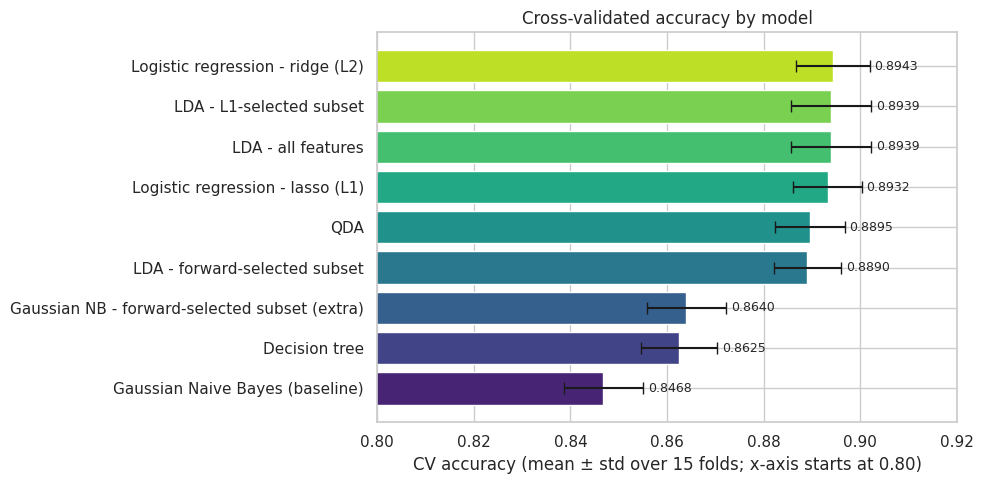

In [27]:
# --- Bar chart: CV accuracy with error bars (error bar = std over the 15 validation folds) -----------------------------------------------------------
order = sorted(RESULTS, key=lambda n: RESULTS[n]["mean"])
means = [RESULTS[n]["mean"] for n in order]
stds = [RESULTS[n]["std"] for n in order]

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(order, means, xerr=stds, capsize=4, color=sns.color_palette("viridis", len(order)))
ax.set_xlim(0.80, 0.92)       # axis is truncated on purpose: all models lie within a few points of each other
for b, m, s in zip(bars, means, stds):
    ax.text(m + s + 0.001, b.get_y() + b.get_height() / 2, f"{m:.4f}", va="center", fontsize=9)
ax.set_xlabel("CV accuracy (mean ± std over 15 folds; x-axis starts at 0.80)")
ax.set_title("Cross-validated accuracy by model")
plt.tight_layout(); plt.show()

### Which differences are real, and which are noise?

All models were scored on the **same 15 folds**, so I can compare them with *paired* differences (fold by fold). Fold scores are not independent
(the training sets overlap), so a plain paired t-test is far too optimistic; I use the **Nadeau-Bengio corrected resampled t-test**,
which inflates the variance by a factor `(1/k + n_test/n_train)`. With many comparisons some p < 0.05 will appear by chance, so read the
table conservatively.

In [28]:
# --- Paired comparison with the best model (corrected resampled t-test) ----------------------------------------------------------------------------------
best_name = max(RESULTS, key=lambda n: RESULTS[n]["mean"])
k = N_SPLITS * N_REPEATS
test_train_ratio = 1 / (N_SPLITS - 1)               # n_test / n_train for 5-fold CV

rows = []
for name, r in RESULTS.items():
    if name == best_name:
        continue
    d = RESULTS[best_name]["fold_scores"] - r["fold_scores"]
    se = np.sqrt((1 / k + test_train_ratio) * d.var(ddof=1))
    t = d.mean() / se if se > 0 else np.inf
    pval = 2 * stats.t.sf(abs(t), df=k - 1)
    rows.append({"Model": name, "mean diff vs best": d.mean(), "corrected SE": se, "t": t, "p-value": pval,
                 "verdict": "within noise" if pval >= 0.05 else "significantly worse"})

print("Best model by mean CV accuracy:", best_name)
display(pd.DataFrame(rows).sort_values("mean diff vs best").round(4).reset_index(drop=True))

Best model by mean CV accuracy: Logistic regression - ridge (L2)


,Model,mean diff vs best,corrected SE,t,p-value,verdict
0,LDA - all features,0.0004,0.0015,0.2656,0.7944,within noise
1,LDA - L1-selected subset,0.0004,0.0015,0.2656,0.7944,within noise
2,Logistic regression - lasso (L1),0.0011,0.0017,0.6295,0.5392,within noise
3,QDA,0.0048,0.0018,2.6778,0.0180,significantly worse
4,LDA - forward-selected subset,0.0052,0.0015,3.4510,0.0039,significantly worse
5,Gaussian NB - forward-selected subset (extra),0.0303,0.0055,5.4725,0.0001,significantly worse
6,Decision tree,0.0318,0.0041,7.8231,0.0000,significantly worse
7,Gaussian Naive Bayes (baseline),0.0475,0.0036,13.3349,0.0000,significantly worse


In [29]:
# --- Optional: nested CV to size the optimism of 'best score from the grid search' --------------------------------------------------
# Outer loop: the same style of CV (1 repeat of stratified 5-fold, same seed); inner loop: 3-fold grid search on each outer-training set.
# This score is NOT used to pick the model - it only shows how much the grid-search scores above are inflated by selection.
if RUN_NESTED:
    outer = RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=1, random_state=SEED)
    nested_rows = []
    for name in ["Logistic regression - ridge (L2)", "LDA - all features", "QDA", "Decision tree"]:
        pipe, grid = SPECS[name]
        inner = GridSearchCV(pipe, grid, cv=StratifiedKFold(3, shuffle=True, random_state=SEED), n_jobs=-1)
        s = cross_val_score(inner, X, y, cv=outer)
        nested_rows.append({"Model": name, "grid-search CV score (Section 5)": RESULTS[name]["mean"],
                            "nested CV score": s.mean(), "nested std": s.std(ddof=1)})
    nested = pd.DataFrame(nested_rows)
    nested["optimism"] = nested["grid-search CV score (Section 5)"] - nested["nested CV score"]
    display(nested.round(4))

,Model,grid-search CV score (Section 5),nested CV score,nested std,optimism
0,Logistic regression - ridge (L2),0.8943,0.8929,0.0071,0.0013
1,LDA - all features,0.8939,0.8929,0.0055,0.0009
2,QDA,0.8895,0.8889,0.0043,0.0006
3,Decision tree,0.8625,0.8628,0.0034,-0.0003


### Discussion of the results

**Three tiers.**
1. **Top tier, a statistical tie (about 0.893 to 0.894):** ridge logistic regression (0.8943 ± 0.0077), LDA (0.8939 ± 0.0083) and lasso
   logistic regression (0.8932 ± 0.0071). The gaps between them are at most about 0.001, roughly one-eighth of the fold-to-fold std, and
   the corrected paired p-values are 0.5 or higher: these differences are **within noise**. The "LDA - L1-selected subset" row is not an
   independent result, because at its best strength the selector keeps all 20 features, so it is the same model as full LDA.
2. **Slightly lower (about 0.889):** QDA (0.8895) and LDA on a forward-selected subset (0.8890), about half a point below the best. The
   paired test gives p ≈ 0.02 and 0.004, but with eight comparisons one or two such p-values can appear by chance, so I read these as
   "probably slightly worse", not as certain.
3. **Clearly worse:** the decision tree (0.8625, about 3 points lower) and Gaussian NB (0.8468, about 5 points lower). These gaps are
   several times the fold std with p < 0.001, so they are **real** differences.

**Why the linear models win.** Ridge logistic regression (a discriminative model) and LDA (a generative model) reach the same accuracy, and
the extra flexibility of QDA does not help (it needs `reg_param = 0.1` to match LDA's neighbourhood and still stays below it). This is
consistent with classes that look roughly Gaussian with similar covariance, i.e. close to linear boundaries. Three differently motivated
models plateauing at about 0.894 suggests that the classes genuinely overlap and that this is near what these features allow, though
this notebook cannot prove that.

**Where the errors are** (confusion matrix in Section 7): class 0 is the hard class. Out-of-fold, class 0 is confused with class 1 (221 and
214 cases) and with class 2 (172 and 164), while classes 1 and 2 are almost never confused with each other (12 and 11 cases).

**Feature selection did not improve accuracy.** Forward selection (10 of 20 features) lost about 0.5 points against all features. L1 selection
keeps all 20 at its best strength, and sparser choices cost accuracy (11 features: 0.8868; 12 features: 0.8906; 19 features: 0.8931). The
lasso zeroes out no feature at its best `C`, and only `cargo_capacity_l` at the one-standard-error `C = 0.05`. So the features are redundant
but each still adds a little information. Selection is useful for a simpler model, not for a better one. The exception is Naive Bayes,
where 3 well-chosen features (`wheelbase_mm`, `acceleration_0_100_kmh_s`, `braking_distance_m`, one per correlated block) gain about 1.7 points,
as predicted in Section 2, but still trail every linear model.

**How optimistic are the tuned scores?** The nested-CV check gives scores only 0.0006 to 0.0013 below the grid-search scores for ridge, LDA and
QDA (and none for the tree), so tuning on the same folds inflated them very little and the ranking is unchanged.

**Duplicates.** On the raw file an unpruned tree scores 0.897, higher than every tuned model here, but only because of leaked twins. Honestly
evaluated it scores 0.825.

**Model choice.** By the stated rule (highest CV mean) the final model is ridge logistic regression. Because LDA and lasso are statistically
indistinguishable from it, I would expect them to score about the same on the test set; ridge logistic regression is a sensible, simple choice.

## 7. Best model, final fit and submission

The final model is **chosen by CV score**, i.e. the configuration with the highest mean accuracy in the table above. It is then refitted
on **all** (de-duplicated) training data and used to predict `vehicle_test.csv`. The test set is only ever used to produce predictions.

First, the confusion matrix of the chosen model from out-of-fold predictions (the first CV repeat, so every training row is predicted by a model that never saw it).

Best model by CV score: Logistic regression - ridge (L2)
  CV accuracy 0.8943 +/- 0.0077
  hyper-parameters: {'model__C': 0.1}


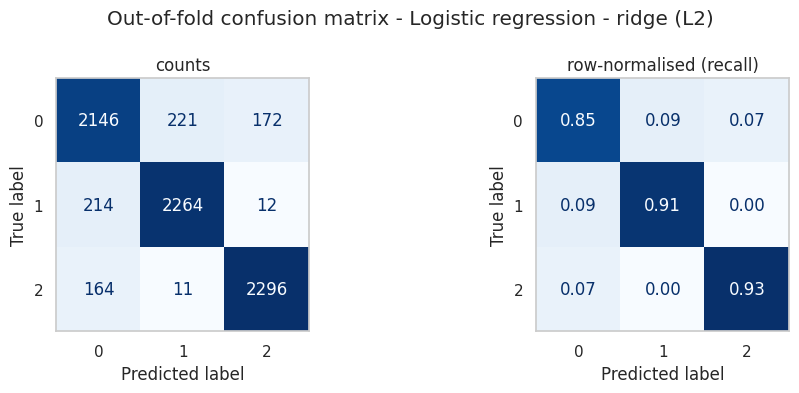

        pred 0  pred 1  pred 2
true 0    2146     221     172
true 1     214    2264      12
true 2     164      11    2296 

              precision    recall  f1-score   support

           0      0.850     0.845     0.848      2539
           1      0.907     0.909     0.908      2490
           2      0.926     0.929     0.927      2471

    accuracy                          0.894      7500
   macro avg      0.894     0.895     0.894      7500
weighted avg      0.894     0.894     0.894      7500



In [30]:
# --- Pick the best model by CV score --------------------------------------------------------------------------------------------------------------------------------------------
best_name = max(RESULTS, key=lambda n: RESULTS[n]["mean"])
best_spec = RESULTS[best_name]
print(f"Best model by CV score: {best_name}")
print(f"  CV accuracy {best_spec['mean']:.4f} +/- {best_spec['std']:.4f}")
print(f"  hyper-parameters: {best_spec['best_params']}")

best_estimator = best_spec["search"].best_estimator_          # pipeline with the winning hyper-parameters
_ = cv_confusion(best_estimator, f"Out-of-fold confusion matrix - {best_name}")

In [31]:
# --- Refit on ALL training data, predict the test set, write submission.csv -----------------------------------------------------------------------------------------------------
final_model = clone(best_estimator).fit(X, y)
print("training accuracy of the final model (optimistic, for reference only):", round(final_model.score(X, y), 4))

test_pred = final_model.predict(X_test)
submission = pd.DataFrame({ID: test[ID].values, TARGET: test_pred.astype(int)})

# Format checks against the sample submission
assert list(submission.columns) == list(sample_sub.columns), "column names differ from the sample submission"
assert len(submission) == len(sample_sub), "row count differs from the sample submission"
assert (submission[ID].values == sample_sub[ID].values).all(), "vehicle_id order differs from the sample submission"
assert submission[TARGET].isin([0, 1, 2]).all()

submission.to_csv("submission.csv", index=False)
print("saved submission.csv", submission.shape)
display(submission.head())
display(submission[TARGET].value_counts(normalize=True).sort_index().round(3).to_frame("share of test predictions"))

training accuracy of the final model (optimistic, for reference only): 0.8964
saved submission.csv (2500, 2)


,vehicle_id,vehicle_class
0,10001,0
1,10002,0
2,10003,1
3,10004,2
4,10005,1


,share of test predictions
vehicle_class,
0,0.335
1,0.332
2,0.333
